## 第5章「消費財の需要を解析する」— サポートページ共通セットアップ

サポートページ全体で使用するパスの設定、DataFrame 表示スタイルの適用、および `matplotlib_fontja` のインポートを行う。あわせて、グラフで使用するグレースケールの色を定義する。


In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break

    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

MONO_BLACK = "0.00"
MONO_DARK = "0.25"
MONO_MID = "0.60"
MONO_LIGHT = "0.85"

# 第5章 消費財の需要を解析する


## 第5章、第4節、第1項のコード

### 入力データの形式とシミュレーションデータの生成

実務では、全対象消費者を列挙した顧客マスター（`consumer_id`, `observation_start`, `observation_end`, `eligible`）と、1行を1回の購買の機会にまとめたPOS明細（`consumer_id`, `transaction_id`, `purchased_at`, `brand`, `quantity`）を用いる。顧客マスターにPOSデータの集計値を左結合し、POSにない対象者の購買回数を0で補う。ここでは、その集計後の形式（`consumer_id`, `n_category`, `n_brand_A`, `n_brand_B`, `n_brand_C`）を直接シミュレーションする。

ここでいう全対象消費者とは、観察期間中に購買の機会を持ち得た分析対象者全員である。会員データだけを使う場合、得られる期間浸透率は会員内の値になるため、対象チャネル、IDの統合方法、観察条件、入退会の扱いを明記する。

NBDのパラメータ $M=3.0$、$K=0.8$ を用いて消費者500人分のカテゴリーの購買データをシミュレーションする。各消費者の購買回数がNBDに従うように、ガンマ分布とポアソン分布を順に用いて生成し、ディリクレ分布からブランドの選択確率を決定する。

#### 処理内容

1. **ライブラリのインポート**
   `polars`と`numpy`をインポートする。

2. **NBDのパラメータの設定**
   観察期間（1年間）の平均購買回数 `M_true=3.0`、購買頻度のばらつきを表す `K_true=0.8`、購買回数ベースの平均市場シェア A:50%、B:30%、C:20% を設定する。

3. **ガンマ分布から観察期間内の期待購買回数を生成**
   `rng.gamma(shape=K_true, scale=M_true/K_true)` で各消費者の観察期間内の期待購買回数を生成する。NumPyでは率ではなく尺度 `M_true/K_true` を指定する。

4. **ポアソン分布から購買回数を生成**
   各消費者の観察期間内の期待購買回数をもとに年間の購買回数を生成する。

5. **ディリクレ分布からブランドの選択確率を生成**
   各消費者のブランドの選択確率を並べたベクトルを生成し、購買回数分をブランドに割り振る。

6. **DataFrame の表示**
   `df.head(5)` で先頭5行を確認する。


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

rng = np.random.default_rng(42)

# NBDのパラメータ
M_true = 3.0  # 観察期間（1年間）の平均購買回数（カテゴリー）
K_true = 0.8  # 購買頻度のばらつきを表す値（小さいほどばらつきが大きい）

# 購買回数ベースの平均市場シェアとディリクレ分布のパラメータ
expected_shares = np.array([0.50, 0.30, 0.20])  # A, B, C
alpha_0 = 10.0
dirichlet_alpha = expected_shares * alpha_0
brand_names = ["A", "B", "C"]
n_consumers = 500

# ガンマ分布から観察期間内のカテゴリーの期待購買回数を生成
# ガンマ分布は理論上 rate=K/M。NumPyでは scale=M/K を指定
mu_i = rng.gamma(shape=K_true, scale=M_true / K_true, size=n_consumers)

# ポアソン分布から購買回数を生成
n_purchases = rng.poisson(lam=mu_i)

# ディリクレ分布からブランドの選択確率を生成
brand_probs = rng.dirichlet(alpha=dirichlet_alpha, size=n_consumers)

# 各対象消費者についてブランドごとの購買回数を集計
records = []
for cid in range(n_consumers):
    n = n_purchases[cid]
    if n > 0:
        chosen = rng.choice(len(brand_names), size=n, p=brand_probs[cid])
        brand_counts = np.bincount(chosen, minlength=len(brand_names))
    else:
        brand_counts = np.zeros(len(brand_names), dtype=int)
    records.append(
        {
            "consumer_id": cid,
            "n_category": int(n),
            "n_brand_A": int(brand_counts[0]),
            "n_brand_B": int(brand_counts[1]),
            "n_brand_C": int(brand_counts[2]),
        }
    )

df = pl.DataFrame(records)

print(
    f"カテゴリーを買った対象消費者数: {(df['n_category'] > 0).sum()} / {n_consumers}"
)
print(
    f"対象消費者1人当たりの平均購買回数（カテゴリー）: {df['n_category'].mean():.3f}"
)

df_head = df.head(5)
df_head

カテゴリーを買った対象消費者数: 355 / 500
対象消費者1人当たりの平均購買回数（カテゴリー）: 2.824


consumer_id,n_category,n_brand_A,n_brand_B,n_brand_C
i64,i64,i64,i64,i64
0,8,1,7,0
1,7,1,6,0
2,0,0,0,0
3,4,3,1,0
4,0,0,0,0


### 購買回数の分布をグラフで確認する

NBDを当てはめる前に、全対象消費者のカテゴリーの購買回数の度数分布を作り、グラフで確認する。
推定と当てはまりを確認するグラフの対象を一致させ、0回購買者と、購買回数が多い側の分布の形を確認する。グラフだけで十分に当てはまるとは判断できない。

#### 処理内容

1. **全対象消費者の保持**
   顧客マスターに相当する `df` をそのまま使い、カテゴリーを0回購買した人も残す。

2. **カテゴリーの購買回数の集計**
   `group_by("n_category")` で購買回数別の人数を集計する。

3. **棒グラフによる確認**
   購買回数の分布を棒グラフで表示する。


0回購買者（全対象消費者中）: 145

カテゴリーの購買回数の分布（実測）:
shape: (20, 2)
┌────────────┬───────┐
│ n_category ┆ count │
│ ---        ┆ ---   │
│ i64        ┆ u32   │
╞════════════╪═══════╡
│ 0          ┆ 145   │
│ 1          ┆ 92    │
│ 2          ┆ 72    │
│ 3          ┆ 45    │
│ 4          ┆ 41    │
│ …          ┆ …     │
│ 16         ┆ 2     │
│ 17         ┆ 2     │
│ 21         ┆ 1     │
│ 23         ┆ 2     │
│ 27         ┆ 1     │
└────────────┴───────┘


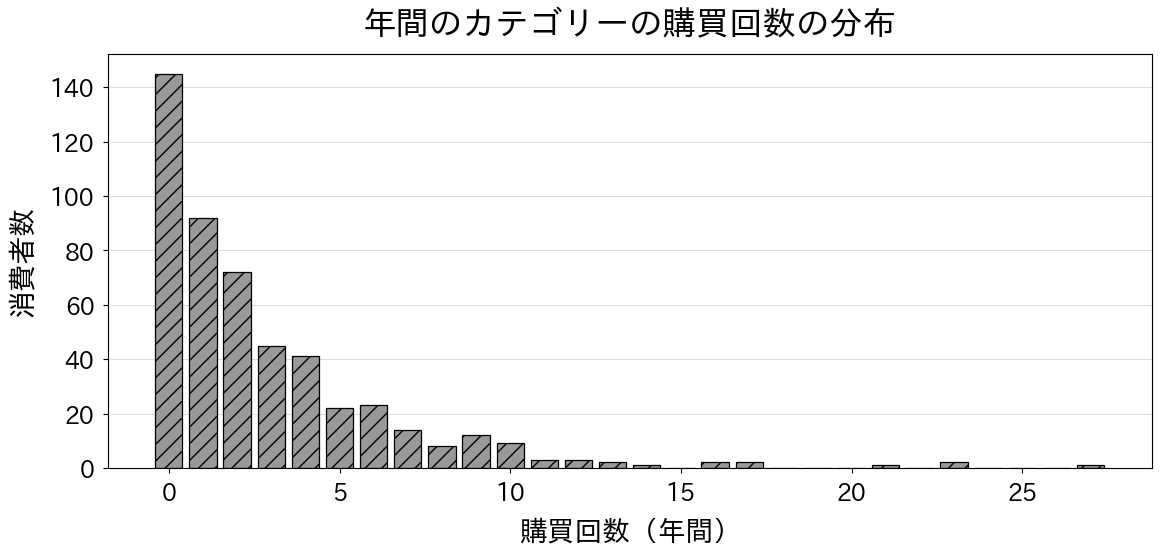

In [4]:
# 全対象消費者のカテゴリーの購買回数の分布を集計
max_n = int(df["n_category"].max()) + 1
freq_obs = (
    df.group_by("n_category").agg(pl.len().alias("count")).sort("n_category")
)

# 顧客マスターに由来する0回購買者を確認
n_zero = df.filter(pl.col("n_category") == 0).height
print(f"0回購買者（全対象消費者中）: {n_zero}")

# 度数分布をPolars DataFrameで整理
print("\nカテゴリーの購買回数の分布（実測）:")
print(freq_obs)

# 棒グラフで確認
counts = [0] * max_n
for row in freq_obs.iter_rows(named=True):
    counts[row["n_category"]] = row["count"]

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(
    range(max_n),
    counts,
    color=MONO_MID,
    edgecolor=MONO_BLACK,
    linewidth=0.9,
    hatch="//",
    label="実測値",
)
ax.set_xlabel("購買回数（年間）", fontsize=20, labelpad=10)
ax.set_ylabel("消費者数", fontsize=20, labelpad=10)
ax.set_title("年間のカテゴリーの購買回数の分布", fontsize=24, pad=14)
ax.tick_params(labelsize=17, pad=6)
ax.grid(axis="y", color=MONO_LIGHT, linewidth=0.7)
ax.set_axisbelow(True)
fig.subplots_adjust(left=0.11, right=0.98, bottom=0.17, top=0.86)
plt.show()

## 第5章、第4節、第2項のコード

### 最尤推定によるNBDのパラメータの推定

前項で生成したシミュレーションデータを用いて、そのデータが得られる確率を最も高くするNBDのパラメータ $(M, K)$ を最尤推定（MLE）で求める。
推定結果と設定値を比較し、モデルの当てはまりをグラフと統計検定で評価する。

#### 処理内容

1. **NBDの対数確率の定義**
   `nbd_logpmf()` で $(M, K)$ 表記のNBDの対数確率を計算する。

2. **負の対数尤度の最小化**
   $M$と$K$が常に正になるように、対数変換したパラメータを `scipy.optimize.minimize` の Nelder-Mead 法で推定し、指数変換で元の尺度に戻す。

3. **初期値**
   モーメント法（標本平均と、`ddof=1`で求めた不偏分散から $\hat{M}=\bar{x}$、$\hat{K}=\bar{x}^2/(s^2-\bar{x})$）で初期値を設定する。


In [5]:
import numpy as np
from scipy import optimize, special

# 前項で生成した df から全対象消費者のカテゴリーの購買回数を取得
x_obs = df["n_category"].to_numpy()


def nbd_logpmf(x: np.ndarray, M: float, K: float) -> np.ndarray:
    """NBDの対数確率（M, K パラメータ表記）"""
    # P(X=x|M,K) = Gamma(x+K)/(Gamma(K)*x!) * (K/(K+M))^K * (M/(K+M))^x
    log_p = (
        special.gammaln(x + K)
        - special.gammaln(K)
        - special.gammaln(x + 1)
        + K * np.log(K / (K + M))
        + x * np.log(M / (K + M))
    )
    return log_p


def neg_loglik(log_params: np.ndarray, x: np.ndarray) -> float:
    """最小化する負の対数尤度"""
    M, K = np.exp(log_params)
    return -np.sum(nbd_logpmf(x, M, K))


# 初期値はモーメント法による推定値を利用
x_mean = x_obs.mean()
x_var = x_obs.var(ddof=1)
K_init = x_mean**2 / (x_var - x_mean) if x_var > x_mean else 1.0
init_log_params = np.log([x_mean, max(K_init, 0.1)])

result = optimize.minimize(
    neg_loglik,
    x0=init_log_params,
    args=(x_obs,),
    method="Nelder-Mead",
    options={"xatol": 1e-6, "fatol": 1e-6, "maxiter": 10000},
)

if not result.success:
    raise RuntimeError(
        f"NBDの最尤推定で安定した値を得られませんでした: {result.message}"
    )

M_hat, K_hat = np.exp(result.x)
print(f"推定M = {M_hat:.4f}  (設定値 {M_true})")
print(f"推定K = {K_hat:.4f}  (設定値 {K_true})")
print(f"最適化成功: {result.success}, 繰り返し回数: {result.nit}")

推定M = 2.8240  (設定値 3.0)
推定K = 0.8327  (設定値 0.8)
最適化成功: True, 繰り返し回数: 41


### 推定結果の確認：実測分布とNBDから計算した分布の比較

推定された $(M, K)$ からNBDの度数分布を計算し、実測値と重ねてモデルの当てはまりを確認する。

#### 処理内容

1. **NBDの確率の計算**
   推定したパラメータで `nbd_logpmf()` を呼び出し、各購買回数についてNBDから計算した確率を求める。

2. **実測度数の計算**
   `np.bincount()` で全対象消費者の購買回数の分布を集計し、割合に変換する。

3. **棒グラフによる比較**
   実測値（濃い灰色・斜線）とNBDから計算した割合（薄い灰色・点模様）を並べた棒グラフを表示する。


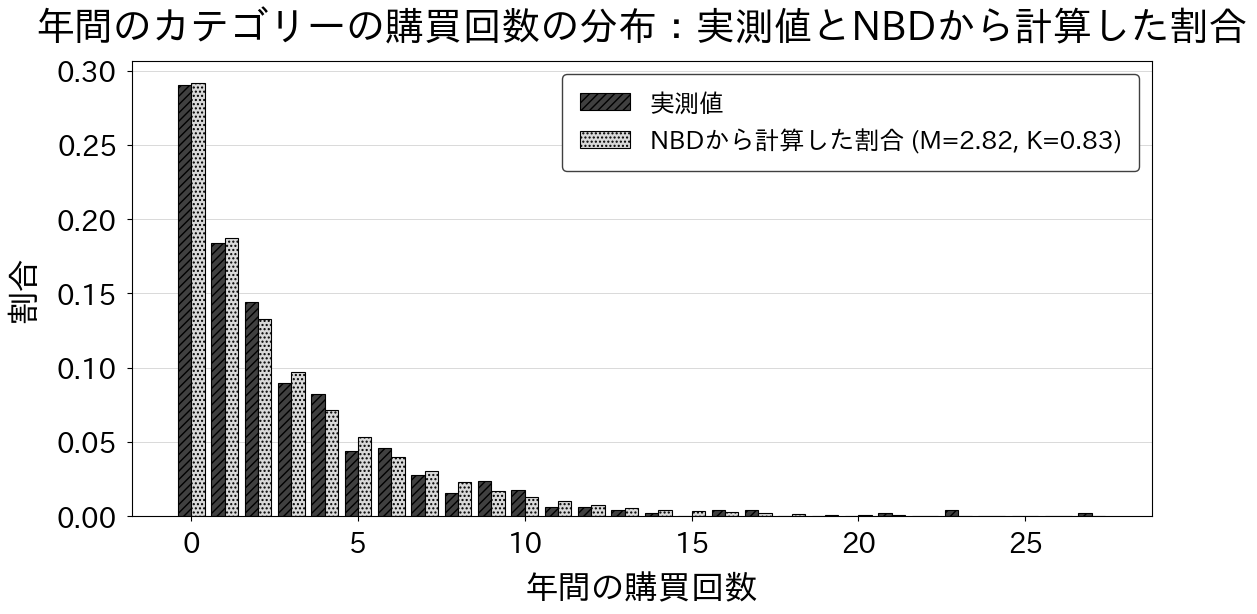

In [6]:
import matplotlib.pyplot as plt

max_x = int(x_obs.max())
x_vals = np.arange(0, max_x + 1)

# NBDから計算した確率
log_pmf_hat = nbd_logpmf(x_vals, M_hat, K_hat)
pmf_hat = np.exp(log_pmf_hat)

# 実測度数（全対象消費者を分母とする）
obs_counts = np.bincount(x_obs, minlength=max_x + 1)
obs_freq = obs_counts / obs_counts.sum()

fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(
    x_vals - 0.2,
    obs_freq,
    width=0.4,
    color=MONO_DARK,
    edgecolor=MONO_BLACK,
    linewidth=0.8,
    hatch="////",
    label="実測値",
)
ax.bar(
    x_vals + 0.2,
    pmf_hat,
    width=0.4,
    color=MONO_LIGHT,
    edgecolor=MONO_BLACK,
    linewidth=0.8,
    hatch="....",
    label=f"NBDから計算した割合 (M={M_hat:.2f}, K={K_hat:.2f})",
)
ax.set_xlabel("年間の購買回数", fontsize=24, labelpad=12)
ax.set_ylabel("割合", fontsize=24, labelpad=12)
ax.set_title(
    "年間のカテゴリーの購買回数の分布：実測値とNBDから計算した割合",
    fontsize=28,
    pad=16,
)
ax.tick_params(labelsize=20, pad=7)
ax.grid(axis="y", color=MONO_LIGHT, linewidth=0.7)
ax.set_axisbelow(True)
ax.legend(
    fontsize=18,
    loc="upper right",
    ncol=1,
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
    framealpha=1.0,
    borderpad=0.7,
)
fig.subplots_adjust(left=0.13, right=0.98, bottom=0.17, top=0.82)
plt.show()

### 当てはまりを数値で確認する：カイ二乗検定

グラフによる目視確認に加えて、カイ二乗適合度検定で実測分布とNBDの間に明確な差があるかを検討する。

#### 処理内容

1. **購買回数の区間をまとめる**
   NBDから予想される人数が5人未満の区間を末尾からまとめ、最後の区間には観測した最大値を超えるNBDの確率も含める。

2. **カイ二乗統計量の計算**
   $\chi^2 = \sum (O_i - E_i)^2 / E_i$ を計算する。自由度は（区間数 - 1 - 推定したパラメータ数2）。

3. **p値の解釈**
   自由度が0以下、またはp値が計算できない場合は、有意差を判定しない。`p > 0.05` はNBDとの差が統計的に有意ではないことを意味する。ただし、NBDが正しいことや、十分に当てはまることの証明ではない。検定結果は標本サイズや区間の分け方に左右されるため、標本が少ない場合は、推定したNBDからデータを繰り返し作って結果のばらつきを確認する。


In [7]:
from scipy.stats import chi2, nbinom

# NBDから予想される人数が5人未満の区間をまとめる（カイ二乗検定の前提条件）
n_total = len(x_obs)
expected = pmf_hat * n_total

# 最後の区間を「cutoff回以上」とし、観測した最大値を超える確率も含める
nbd_prob = K_hat / (K_hat + M_hat)  # scipy.stats.nbinomの成功確率
cutoff = max_x
while expected[cutoff] < 5 and cutoff > 1:
    cutoff -= 1

obs_merged = np.append(obs_counts[:cutoff], obs_counts[cutoff:].sum())
tail_expected = nbinom.sf(cutoff - 1, K_hat, nbd_prob) * n_total
exp_merged = np.append(expected[:cutoff], tail_expected)

chi2_stat = np.sum((obs_merged - exp_merged) ** 2 / exp_merged)
df_chi2 = len(obs_merged) - 1 - 2  # 推定したパラメータ数=2 を引く
p_value = chi2.sf(chi2_stat, df=df_chi2)

print(f"chi^2 = {chi2_stat:.3f}, df = {df_chi2}, p = {p_value:.4f}")
if df_chi2 <= 0 or not np.isfinite(p_value):
    print("→ 検定条件を満たしていないため、有意差を判定できません")
elif p_value > 0.05:
    print("→ NBDとの差は統計的に有意ではありませんでした（p > 0.05）")
else:
    print("→ NBDとの差は統計的に有意です（p <= 0.05）")

chi^2 = 6.875, df = 9, p = 0.6501
→ NBDとの差は統計的に有意ではありませんでした（p > 0.05）


## 第5章、第4節、第3項のコード

### ブランドごとの対象消費者1人当たりの平均購買回数を求める

推定したカテゴリー全体のNBDのパラメータ $(\hat{M}, \hat{K})$ から、ブランドごとの期間浸透率と、そのブランドを買った人1人当たりの平均購買回数を計算する。
ブランド $j$ の対象消費者1人当たりの平均購買回数を $M_j = \hat{M} \cdot s_j$ とし、共通の $\hat{K}$ を用いて簡単に計算する。

#### 処理内容

1. **ブランドの購買回数ベースの市場シェアの計算**
   各ブランドの購買回数合計をカテゴリー全体の購買回数で割り、購買回数ベースの市場シェアを計算する。

2. **期間浸透率の計算**
   `nbd_penetration(Mj, K_cat)` で $b_j = 1 - (K/(K+M_j))^K$ を計算する。

3. **ブランドを買った人1人当たりの平均購買回数の計算**
   `nbd_frequency(Mj, K_cat)` で $w_j = M_j / b_j$ を計算する。

4. **DataFrame の表示**
   計算用の列名を日本語の表示名へ変更した `display_df` を作成し、結果を分かりやすく表示する。


In [8]:
import polars as pl

# 推定されたカテゴリー全体のNBDのパラメータ
M_cat = M_hat  # 前項で推定
K_cat = K_hat

# ブランドの購買回数ベースの市場シェアを計算
n_total_purchases = df["n_category"].sum()
share_A = df["n_brand_A"].sum() / n_total_purchases
share_B = df["n_brand_B"].sum() / n_total_purchases
share_C = df["n_brand_C"].sum() / n_total_purchases

brands = ["A", "B", "C"]
shares = [share_A, share_B, share_C]


def nbd_penetration(M: float, K: float) -> float:
    """期間浸透率 b = 1 - P(X=0|M,K)"""
    return 1.0 - (K / (K + M)) ** K


def nbd_frequency(M: float, K: float) -> float:
    """1回以上買った人1人当たりの平均購買回数 w = M / b"""
    b = nbd_penetration(M, K)
    return M / b if b > 0 else 0.0


rows = []
for brand, s in zip(brands, shares):
    Mj = M_cat * s
    bj = nbd_penetration(Mj, K_cat)
    wj = nbd_frequency(Mj, K_cat)
    rows.append(
        {
            "brand": brand,
            "share_pct": round(s * 100, 1),
            "M_j": round(Mj, 3),
            "penetration_pct": round(bj * 100, 1),
            "avg_freq": round(wj, 3),
        }
    )

result_df = pl.DataFrame(rows)
display_df = result_df.rename(
    {
        "brand": "ブランド",
        "share_pct": "市場シェア\n（%）",
        "M_j": "M_j",
        "penetration_pct": "期間浸透率\n（%）",
        "avg_freq": "ブランドを買った人\n1人当たりの平均購買回数",
    }
)
display_df

ブランド,市場シェア （%）,M_j,期間浸透率 （%）,ブランドを買った人 1人当たりの平均購買回数
str,f64,f64,f64,f64
"""A""",51.0,1.44,56.7,2.542
"""B""",29.0,0.82,43.5,1.885
"""C""",20.0,0.564,35.0,1.612


### 実測値と比較用の理論値を比べる

共通の $K$ を用いた簡略化したモデルの比較用の理論値と実測値を並べ、差の有無を確認する。
実測した期間浸透率は「ブランド $j$ を1回以上買った対象消費者の割合」、実測した平均購買回数は「ブランド $j$ の総購買回数を、そのブランドを1回以上買った人数で割った値」である。

ここで示す比較用の理論値と実測値は、どちらも1つの値として求めた結果である。実務では、対象消費者を繰り返し抽出して計算し直し、$M$、$K$とブランドごとの指標がどの程度変わるかも確認する。その変化の幅より差が十分に大きい場合に、追加調査や施策を検討する。

#### 処理内容

1. **実測した期間浸透率の計算**
   各ブランドを1回以上買った人数（`n_brand_X > 0`）を全対象消費者数で割る。

2. **ブランドを買った人1人当たりの平均購買回数の計算**
   ブランドを1回以上買った人について、`n_brand_X` 列の平均値を計算する。

3. **実測値と比較用の理論値を同じ行に並べて表示**
   両者を同じ行に並べ、列名を日本語化した表で比較する。


In [10]:
# 実測値を計算
n_consumers_total = df.height

obs_rows = []
for brand, s in zip(brands, shares):
    col = f"n_brand_{brand}"
    buyers = df.filter(pl.col(col) > 0)
    b_obs = buyers.height / n_consumers_total
    w_obs = buyers[col].mean()
    Mj = M_cat * s
    b_theory = nbd_penetration(Mj, K_cat)
    w_theory = nbd_frequency(Mj, K_cat)
    obs_rows.append(
        {
            "brand": brand,
            "share_pct": round(s * 100, 1),
            "penetration_obs": round(b_obs * 100, 1),
            "penetration_theory": round(b_theory * 100, 1),
            "freq_obs": round(w_obs, 3),
            "freq_theory": round(w_theory, 3),
        }
    )

compare_df = pl.DataFrame(obs_rows)
compare_display_df = compare_df.rename(
    {
        "brand": "ブランド",
        "share_pct": "市場シェア\n（%）",
        "penetration_obs": "期間浸透率\n実測値（%）",
        "penetration_theory": "期間浸透率\n比較用の理論値（%）",
        "freq_obs": "ブランドを買った人\n1人当たりの平均購買回数\n（実測値）",
        "freq_theory": "ブランドを買った人\n1人当たりの平均購買回数\n（比較用の理論値）",
    }
)
compare_display_df

ブランド,市場シェア （%）,期間浸透率 実測値（%）,期間浸透率 比較用の理論値（%）,ブランドを買った人 1人当たりの平均購買回数 （実測値）,ブランドを買った人 1人当たりの平均購買回数 （比較用の理論値）
str,f64,f64,f64,f64,f64
"""A""",51.0,54.6,56.7,2.637,2.542
"""B""",29.0,43.0,43.5,1.907,1.885
"""C""",20.0,29.8,35.0,1.893,1.612


### ダブルジョパディの確認：ブランドの間の比較

5つのブランドを仮定し、共通の $K$ を用いた簡略化したモデルが予測する、購買回数ベースの市場シェアと期間浸透率、そのブランドを買った人1人当たりの平均購買回数の関係を図にする。これは実測データによるダブルジョパディの確認ではなく、比較用の理論値を示す図である。

#### 処理内容

1. **5ブランド分の比較データの生成**
   市場シェア35%・25%・20%・13%・7%の5ブランドについて、期間浸透率と、そのブランドを買った人1人当たりの平均購買回数を計算する。

2. **散布図の作成**
   左に市場シェアと期間浸透率、右に市場シェアと、そのブランドを買った人1人当たりの平均購買回数を示す。


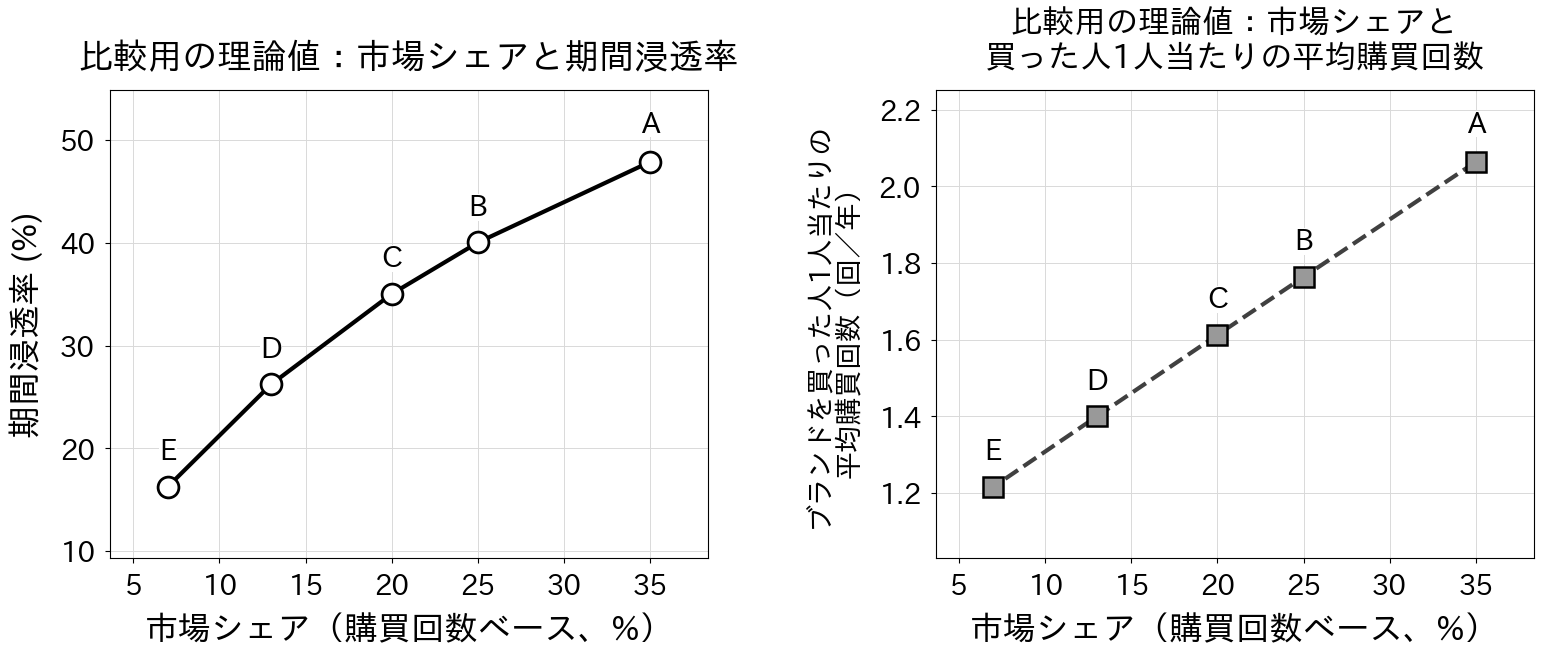

In [12]:
import matplotlib.pyplot as plt

# 5ブランド分の比較（シェアを調整）
ext_brands = ["A", "B", "C", "D", "E"]
ext_shares = [0.35, 0.25, 0.20, 0.13, 0.07]

ext_rows = []
for brand, s in zip(ext_brands, ext_shares):
    Mj = M_cat * s
    bj = nbd_penetration(Mj, K_cat)
    wj = nbd_frequency(Mj, K_cat)
    ext_rows.append(
        {
            "brand": brand,
            "share_pct": s * 100,
            "penetration_pct": bj * 100,
            "avg_freq": wj,
        }
    )

ext_df = pl.DataFrame(ext_rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.2))

label_offsets = {
    "A": (0, 18),
    "B": (0, 16),
    "C": (0, 16),
    "D": (0, 16),
    "E": (0, 16),
}

axes[0].plot(
    ext_df["share_pct"],
    ext_df["penetration_pct"],
    color=MONO_BLACK,
    linestyle="-",
    linewidth=3.0,
    marker="o",
    markersize=15,
    markerfacecolor="white",
    markeredgecolor=MONO_BLACK,
    markeredgewidth=2.0,
)
axes[0].set_xlabel("市場シェア（購買回数ベース、%）", fontsize=24, labelpad=12)
axes[0].set_ylabel("期間浸透率 (%)", fontsize=24, labelpad=12)
axes[0].set_title("比較用の理論値：市場シェアと期間浸透率", fontsize=25, pad=16)
for row in ext_df.iter_rows(named=True):
    axes[0].annotate(
        row["brand"],
        (row["share_pct"], row["penetration_pct"]),
        textcoords="offset points",
        xytext=label_offsets[row["brand"]],
        ha="center",
        va="bottom",
        fontsize=21,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.25},
    )

axes[1].plot(
    ext_df["share_pct"],
    ext_df["avg_freq"],
    color=MONO_DARK,
    linestyle="--",
    linewidth=3.0,
    marker="s",
    markersize=14,
    markerfacecolor=MONO_MID,
    markeredgecolor=MONO_BLACK,
    markeredgewidth=1.8,
)
axes[1].set_xlabel("市場シェア（購買回数ベース、%）", fontsize=24, labelpad=12)
axes[1].set_ylabel(
    "ブランドを買った人1人当たりの\n平均購買回数（回／年）",
    fontsize=20,
    labelpad=12,
)
axes[1].set_title(
    "比較用の理論値：市場シェアと\n買った人1人当たりの平均購買回数",
    fontsize=23,
    pad=16,
)
for row in ext_df.iter_rows(named=True):
    axes[1].annotate(
        row["brand"],
        (row["share_pct"], row["avg_freq"]),
        textcoords="offset points",
        xytext=label_offsets[row["brand"]],
        ha="center",
        va="bottom",
        fontsize=21,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.25},
    )

for ax in axes:
    ax.tick_params(labelsize=20, pad=7)
    ax.margins(x=0.12, y=0.22)
    ax.grid(True, color=MONO_LIGHT, linewidth=0.7)
    ax.set_axisbelow(True)

fig.subplots_adjust(left=0.09, right=0.98, bottom=0.18, top=0.83, wspace=0.38)
plt.show()